In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("../data/raw/measures_v2.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Dataset shape:", df.shape)

Rows: 1330816
Columns: 13
Dataset shape: (1330816, 13)


In [5]:
df.head()

,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [6]:
df.tail()

,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
1330811,-2.152128,30.721298,45.274497,0.791801,41.934347,0.000380,-2.000169,1.097528,62.147780,38.653720,23.989078,-8.116730e-60,71
1330812,-2.258684,30.721306,45.239017,0.778900,41.868923,0.002985,-2.000499,1.097569,62.142646,38.656328,23.970700,-5.815891e-60,71
1330813,-2.130312,30.721312,45.211576,0.804914,41.804819,0.002301,-1.999268,1.098765,62.138387,38.650923,23.977234,-4.167268e-60,71
1330814,-2.268498,30.721316,45.193508,0.763091,41.762220,0.005662,-2.000999,1.095696,62.133422,38.655686,24.001421,-2.985978e-60,71
1330815,-2.100158,30.721319,45.132307,0.807309,41.734763,0.004395,-2.000792,1.096487,62.131429,38.660370,24.027522,-2.139547e-60,71


In [7]:
print("Columns in dataset:")
for i, column in enumerate(df.columns, start=1):
    print(i, "→", column)

Columns in dataset:
1 → u_q
2 → coolant
3 → stator_winding
4 → u_d
5 → stator_tooth
6 → motor_speed
7 → i_d
8 → i_q
9 → pm
10 → stator_yoke
11 → ambient
12 → torque
13 → profile_id


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1330816 entries, 0 to 1330815
Data columns (total 13 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   u_q             1330816 non-null  float64
 1   coolant         1330816 non-null  float64
 2   stator_winding  1330816 non-null  float64
 3   u_d             1330816 non-null  float64
 4   stator_tooth    1330816 non-null  float64
 5   motor_speed     1330816 non-null  float64
 6   i_d             1330816 non-null  float64
 7   i_q             1330816 non-null  float64
 8   pm              1330816 non-null  float64
 9   stator_yoke     1330816 non-null  float64
 10  ambient         1330816 non-null  float64
 11  torque          1330816 non-null  float64
 12  profile_id      1330816 non-null  int64  
dtypes: float64(12), int64(1)
memory usage: 132.0 MB


In [9]:
df.describe()

,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
count,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06,1.330816e+06
mean,5.427900e+01,3.622999e+01,6.634275e+01,-2.513381e+01,5.687858e+01,2.202081e+03,-6.871681e+01,3.741278e+01,5.850678e+01,4.818796e+01,2.456526e+01,3.110603e+01,4.079306e+01
std,4.417323e+01,2.178615e+01,2.867206e+01,6.309197e+01,2.295223e+01,1.859663e+03,6.493323e+01,9.218188e+01,1.900150e+01,1.999100e+01,1.929522e+00,7.713575e+01,2.504549e+01
min,-2.529093e+01,1.062375e+01,1.858582e+01,-1.315304e+02,1.813398e+01,-2.755491e+02,-2.780036e+02,-2.934268e+02,2.085696e+01,1.807669e+01,8.783478e+00,-2.464667e+02,2.000000e+00
25%,1.206992e+01,1.869814e+01,4.278796e+01,-7.869090e+01,3.841601e+01,3.171107e+02,-1.154061e+02,1.095863e+00,4.315158e+01,3.199033e+01,2.318480e+01,-1.374265e-01,1.700000e+01
50%,4.893818e+01,2.690014e+01,6.511013e+01,-7.429755e+00,5.603635e+01,1.999977e+03,-5.109376e+01,1.577401e+01,6.026629e+01,4.562551e+01,2.479733e+01,1.086035e+01,4.300000e+01
75%,9.003439e+01,4.985749e+01,8.814114e+01,1.470271e+00,7.558668e+01,3.760639e+03,-2.979688e+00,1.006121e+02,7.200837e+01,6.146083e+01,2.621702e+01,9.159718e+01,6.500000e+01
max,1.330370e+02,1.015985e+02,1.413629e+02,1.314698e+02,1.119464e+02,6.000015e+03,5.189670e-02,3.017079e+02,1.136066e+02,1.011480e+02,3.071420e+01,2.610057e+02,8.100000e+01


In [10]:
missing_df = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_df = missing_df.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_df

,Missing Values,Missing Percentage
u_q,0,0.0
coolant,0,0.0
stator_winding,0,0.0
u_d,0,0.0
stator_tooth,0,0.0
motor_speed,0,0.0
i_d,0,0.0
i_q,0,0.0
pm,0,0.0
stator_yoke,0,0.0


In [11]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [12]:
duplicate_percentage = (duplicate_count / len(df)) * 100

print(f"Duplicate percentage: {duplicate_percentage:.4f}%")

Duplicate percentage: 0.0000%


In [13]:
numeric_cols = df.select_dtypes(include=np.number).columns

infinite_values = np.isinf(df[numeric_cols]).sum()

print(infinite_values)

print(
    "Total infinite values:",
    np.isinf(df[numeric_cols]).sum().sum()
)

u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64
Total infinite values: 0


In [14]:
print("Number of unique profiles:", df["profile_id"].nunique())

Number of unique profiles: 69


In [15]:
df["profile_id"].value_counts().head(20)

profile_id
20    43971
6     40388
65    40094
18    37732
66    36476
13    35906
27    35361
4     33424
58    33382
56    33123
53    32442
79    31154
44    26341
70    25677
62    25600
30    23863
80    23824
74    23761
68    23331
36    22609
Name: count, dtype: int64

In [16]:
target = df["stator_winding"]

print("Target name:", target.name)
print("Missing:", target.isnull().sum())
print("Minimum:", target.min())
print("Maximum:", target.max())
print("Mean:", target.mean())
print("Median:", target.median())
print("Standard deviation:", target.std())

Target name: stator_winding
Missing: 0
Minimum: 18.5858154296875
Maximum: 141.36288452148438
Mean: 66.34274539496708
Median: 65.11012887949082
Standard deviation: 28.672060878743295


In [17]:
print(df.columns.tolist())

['u_q', 'coolant', 'stator_winding', 'u_d', 'stator_tooth', 'motor_speed', 'i_d', 'i_q', 'pm', 'stator_yoke', 'ambient', 'torque', 'profile_id']


In [18]:
print("========== DATASET AUDIT ==========")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Total missing values: {df.isnull().sum().sum():,}")
print(f"Total infinite values: {np.isinf(df[numeric_cols]).sum().sum():,}")
print(f"Unique profiles: {df['profile_id'].nunique():,}")
print("====================================")

========== DATASET AUDIT ==========
Rows: 1,330,816
Columns: 13
Duplicate rows: 0
Total missing values: 0
Total infinite values: 0
Unique profiles: 69


In [19]:
# Numerical range audit

numeric_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Minimum": df.min(),
    "Maximum": df.max(),
    "Mean": df.mean(),
    "Median": df.median(),
    "Std Dev": df.std()
})

numeric_summary

,Data Type,Minimum,Maximum,Mean,Median,Std Dev
u_q,float64,-25.290930,133.036994,54.279005,48.938181,44.173234
coolant,float64,10.623751,101.598512,36.229995,26.900141,21.786149
stator_winding,float64,18.585815,141.362885,66.342745,65.110129,28.672061
u_d,float64,-131.530411,131.469788,-25.133809,-7.429755,63.091972
stator_tooth,float64,18.133976,111.946423,56.878582,56.036345,22.952233
motor_speed,float64,-275.549144,6000.015137,2202.080728,1999.976685,1859.663350
i_d,float64,-278.003632,0.051897,-68.716810,-51.093763,64.933233
i_q,float64,-293.426793,301.707855,37.412782,15.774007,92.181880
pm,float64,20.856956,113.606628,58.506776,60.266287,19.001498
stator_yoke,float64,18.076689,101.147964,48.187965,45.625509,19.991004


In [20]:
print("Profile IDs:")
print(sorted(df["profile_id"].unique()))

Profile IDs:
[np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(26), np.int64(27), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(36), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(72), np.int64(73), np.int64(74), np.int64(75), np.int64(76), np.int64(78), np.int64(79), np.int64(80), np.int64(81)]


In [21]:
print("Number of profiles:", df["profile_id"].nunique())

Number of profiles: 69


In [22]:
profile_counts = df["profile_id"].value_counts().sort_index()

profile_counts

profile_id
2     19357
3     19248
4     33424
5     14788
6     40388
7     14651
8     18757
9     20336
10    15256
11     7887
12    21942
13    35906
14    18598
15    18124
16    20645
17    15964
18    37732
19    10410
20    43971
21    17321
23    11856
24    15015
26    16666
27    35361
29    21358
30    23863
31    15587
32    20960
36    22609
41    16700
42    16920
43     8443
44    26341
45    17142
46     2180
47     2176
48    21983
49    10816
50    10810
51     6261
52     3726
53    32442
54    10807
55    10807
56    33123
57    14403
58    33382
59     7475
60    14543
61    14516
62    25600
63    16668
64     6250
65    40094
66    36476
67    11135
68    23331
69    15350
70    25677
71    14656
72    15301
73    16786
74    23761
75    13472
76    22188
78     8445
79    31154
80    23824
81    17672
Name: count, dtype: int64

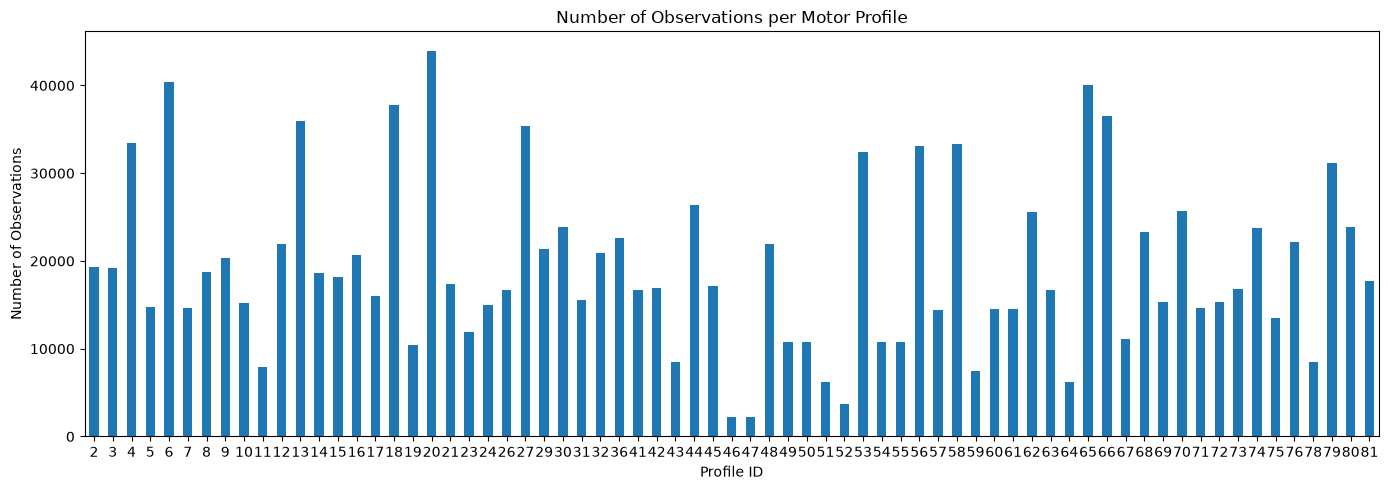

In [23]:
plt.figure(figsize=(14, 5))

profile_counts.plot(kind="bar")

plt.title("Number of Observations per Motor Profile")
plt.xlabel("Profile ID")
plt.ylabel("Number of Observations")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

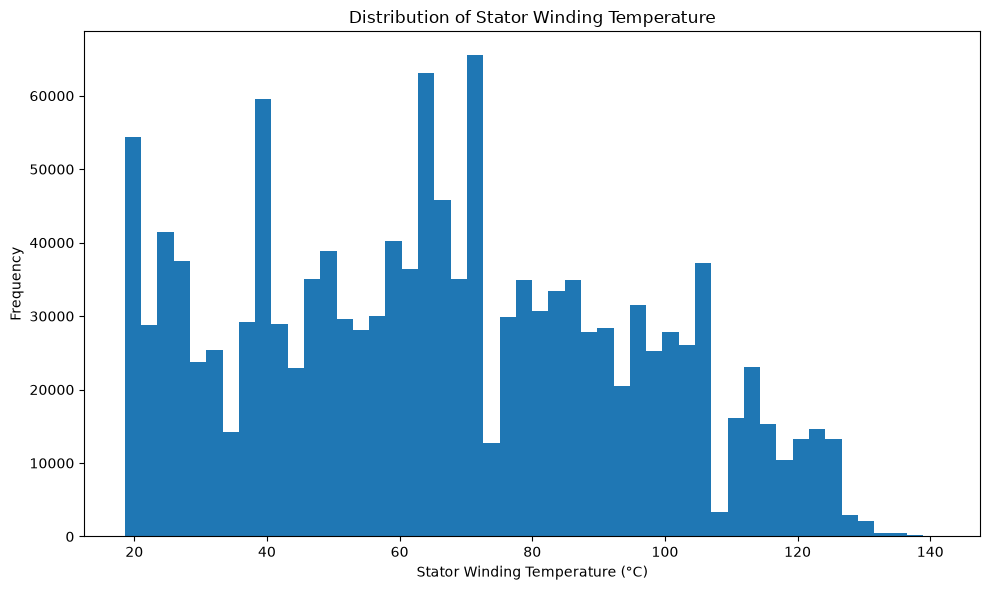

In [24]:
plt.figure(figsize=(10, 6))

plt.hist(df["stator_winding"], bins=50)

plt.title("Distribution of Stator Winding Temperature")
plt.xlabel("Stator Winding Temperature (°C)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

C:\Users\lenovo\AppData\Local\Temp\ipykernel_16928\963110306.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["stator_winding"], vert=False)


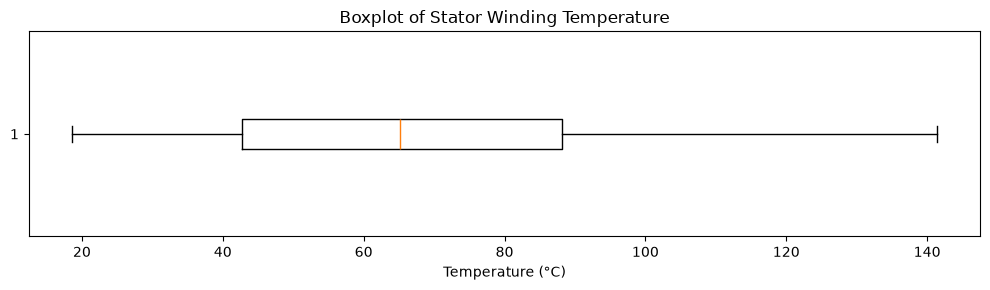

In [25]:
plt.figure(figsize=(10, 3))

plt.boxplot(df["stator_winding"], vert=False)

plt.title("Boxplot of Stator Winding Temperature")
plt.xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()

In [26]:
correlation = df.corr(numeric_only=True)

correlation["stator_winding"].sort_values(ascending=False)

stator_winding    1.000000
stator_tooth      0.970135
stator_yoke       0.860268
pm                0.795893
coolant           0.504835
motor_speed       0.432034
profile_id        0.340580
ambient           0.333208
torque            0.095510
i_q               0.065617
u_q               0.050610
u_d              -0.234950
i_d              -0.624370
Name: stator_winding, dtype: float64